# Customer Segmentation with Clustering

**Author:** Thein Than Arkar
**Context:** University of Cambridge (PACE) Data Science Career Accelerator – Course 1 mini-project

## Overview
This notebook groups 68,300 customers of a global e-commerce business into segments for targeted marketing. It uses SAS's public CUSTOMERS_CLEAN dataset: 951,668 orders from 47 countries, 2012–2016.

## Steps
1. Clean the data (duplicates, missing values, currency and date formats)
2. Engineer five customer-level features: **Frequency, Recency, Customer Lifetime Value (CLV), Average Unit Cost and Age**
3. Explore the features and check outliers with the IQR rule
4. Scale the features with a `StandardScaler` pipeline
5. Choose the number of clusters with the **elbow method, silhouette scores and a Ward-linkage dendrogram**
6. Run **K-Means (k = 4)** and profile each segment
7. Visualise the segments in 2D with **PCA and t-SNE**


## 1. Libraries




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

data = pd.read_csv('https://github.com/FourthRevGitHub/CAM_DS_Public-Data-Sets/raw/main/Course%201/Week%206/CUSTOMERS_CLEAN.zip')
data.head()

,Quantity,City,Continent,Postal_Code,State_Province,Order_Date,Delivery_Date,Total Revenue,Unit Cost,Discount,OrderTypeLabel,CustomerCountryLabel,Customer_BirthDate,Customer_Group,Customer_Type,Order ID,Profit,Days to Delivery,Loyalty Num,Customer ID
0,3,Leinster,Oceania,6437,Western Australia,01JAN2012,07JAN2012,$28.50,$9.10,.,Internet Sale,Australia,08MAY1978,Internet/Catalog Customers,Internet/Catalog Customers,1230000033,$1.20,6,99,8818
1,2,Berowra,Oceania,2081,New South Wales,01JAN2012,04JAN2012,$113.40,$56.90,.,Internet Sale,Australia,13DEC1978,Orion Club Gold members,Orion Club Gold members high activity,1230000204,($0.40),3,99,47793
2,2,Berowra,Oceania,2081,New South Wales,01JAN2012,04JAN2012,$41.00,$18.50,.,Internet Sale,Australia,13DEC1978,Orion Club Gold members,Orion Club Gold members high activity,1230000204,$4.00,3,99,47793
3,1,Northbridge,Oceania,2063,New South Wales,01JAN2012,03JAN2012,$35.20,$29.60,.,Internet Sale,Australia,22JUN1997,Orion Club Gold members,Orion Club Gold members high activity,1230000268,$5.60,2,0,71727
4,1,Montréal,North America,NaN,Quebec,01JAN2012,04JAN2012,$24.70,$23.60,.,Internet Sale,Canada,28JAN1978,Orion Club Gold members,Orion Club Gold members medium activity,1230000487,$1.10,3,99,74503


## 2. Data pre-processing

In [2]:
# Check for missing values.
print("Missing values per column:")
print(data.isnull().sum())

# Check for duplicate rows.
print("\nNumber of duplicate rows:")
print(data.duplicated().sum())

Missing values per column:
Quantity                     0
City                       135
Continent                    0
Postal_Code               3716
State_Province          117192
Order_Date                   0
Delivery_Date                0
Total Revenue                0
Unit Cost                    0
Discount                     0
OrderTypeLabel               0
CustomerCountryLabel         0
Customer_BirthDate           0
Customer_Group               0
Customer_Type                0
Order ID                     0
Profit                       0
Days to Delivery             0
Loyalty Num                  0
Customer ID                  0
dtype: int64

Number of duplicate rows:
21


The dataset contains 21 duplicate rows and significant missing data, most notably 117,192 missing values for State_Province, along with 3,716 missing for Postal_Code and 135 for City.

These finding suggest that the data needs cleaning.
1. Drop 21 duplicate rows
2. Drop column State_Provience  as it is not consider critical for customer segmentation
3. Drop column 'City' as it is not used in any of the 5 core features.
4. Drop column 'Postal_Code' due to a significant number of missing values and its non-direct role in the 5 core features.




In [3]:
data.describe()

,Quantity,Order ID,Days to Delivery,Loyalty Num,Customer ID
count,951669.000000,9.516690e+05,951669.000000,951669.000000,951669.000000
mean,1.678438,1.236943e+09,1.056107,66.534079,45440.602683
std,0.899914,4.273202e+06,2.065725,46.476795,27214.145206
min,1.000000,1.230000e+09,0.000000,0.000000,1.000000
25%,1.000000,1.233081e+09,0.000000,0.000000,22139.000000
50%,1.000000,1.236755e+09,0.000000,99.000000,44140.000000
75%,2.000000,1.240689e+09,1.000000,99.000000,70411.000000
max,10.000000,1.244338e+09,32.000000,99.000000,94254.000000


In [4]:

# Clean the dataset in one go
data.drop_duplicates(inplace=True)
data.drop(["State_Province", "Postal_Code"], axis=1, inplace=True)
data.drop(["City"], axis=1, inplace=True)  # City not used in 5 features; drop column rather than rows

# Verify results
print("Columns remaining in dataset:")
print(data.columns)

print("\nMissing values per column:")
print(data.isnull().sum())

Columns remaining in dataset:
Index(['Quantity', 'Continent', 'Order_Date', 'Delivery_Date', 'Total Revenue',
       'Unit Cost', 'Discount', 'OrderTypeLabel', 'CustomerCountryLabel',
       'Customer_BirthDate', 'Customer_Group', 'Customer_Type', 'Order ID',
       'Profit', 'Days to Delivery', 'Loyalty Num', 'Customer ID'],
      dtype='object')

Missing values per column:
Quantity                0
Continent               0
Order_Date              0
Delivery_Date           0
Total Revenue           0
Unit Cost               0
Discount                0
OrderTypeLabel          0
CustomerCountryLabel    0
Customer_BirthDate      0
Customer_Group          0
Customer_Type           0
Order ID                0
Profit                  0
Days to Delivery        0
Loyalty Num             0
Customer ID             0
dtype: int64


## 3. Feature Engineering
Create 5 new features:
1.   Frequency
2.   Recency
3.  Customer lifetime value (CLV)
4. Average unit cost
5. Customer age



The code below creates five customer-centric features by aggregating raw transaction data at the individual customer level. This step transforms transactional logs into a clean summary table for segmentation.

In [5]:
# Consolidated Feature Engineering Block

# 1. Currency cleaning function
def clean_currency(value):
    if isinstance(value, str):
        return float(value.replace('$', '').replace(',', '').replace('(', '-').replace(')', ''))
    return float(value)

# Parse SAS-format dates (e.g. '01JAN2012') with explicit format to avoid misparse
data['Order_Date']         = pd.to_datetime(data['Order_Date'],         format='%d%b%Y')
data['Delivery_Date']      = pd.to_datetime(data['Delivery_Date'],      format='%d%b%Y')
data['Customer_BirthDate'] = pd.to_datetime(data['Customer_BirthDate'], format='%d%b%Y')

# 2. Clean currency columns
data['Total Revenue'] = data['Total Revenue'].apply(clean_currency)
data['Unit Cost']     = data['Unit Cost'].apply(clean_currency)

# 3. Reference date = today (Recency is always relative to when you run the analysis)
#    The sample answer was produced in ~Dec 2024, At the Time of the running this is what i got, it will be a different number each days as it update)
reference_date = pd.Timestamp('today').normalize()
print(f"Reference date: {reference_date.date()}")

# 4. Customer age as of the reference date (guide formula: elapsed days // 365)
data['Age'] = (reference_date - data['Customer_BirthDate']).dt.days // 365

# 5. Aggregate into one row per customer
#    Recency uses Delivery_Date (the date the customer last received an order)
customer_data = data.groupby('Customer ID').agg(
    Frequency=    ('Order ID',       'nunique'),
    Recency=      ('Delivery_Date',  lambda x: (reference_date - x.max()).days),
    Avg_Unit_Cost=('Unit Cost',      'mean'),
    CLV=          ('Total Revenue',  'sum'),
    Age=          ('Age',            'first')
)

print("\n5 new features:")
display(customer_data.head())
customer_data.info()

Reference date: 2026-06-29

5 new features:


,Frequency,Recency,Avg_Unit_Cost,CLV,Age
Customer ID,,,,,
1,28,3485,89.622857,4322.70,72
3,14,3587,90.505000,2821.00,43
4,8,4576,37.195556,782.67,43
5,15,3473,107.947368,2810.98,38
6,13,3658,52.526667,1604.58,67


<class 'pandas.core.frame.DataFrame'>
Index: 68300 entries, 1 to 94254
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Frequency      68300 non-null  int64  
 1   Recency        68300 non-null  int64  
 2   Avg_Unit_Cost  68300 non-null  float64
 3   CLV            68300 non-null  float64
 4   Age            68300 non-null  int64  
dtypes: float64(2), int64(3)
memory usage: 3.1 MB


## 4. Perform (EDA)

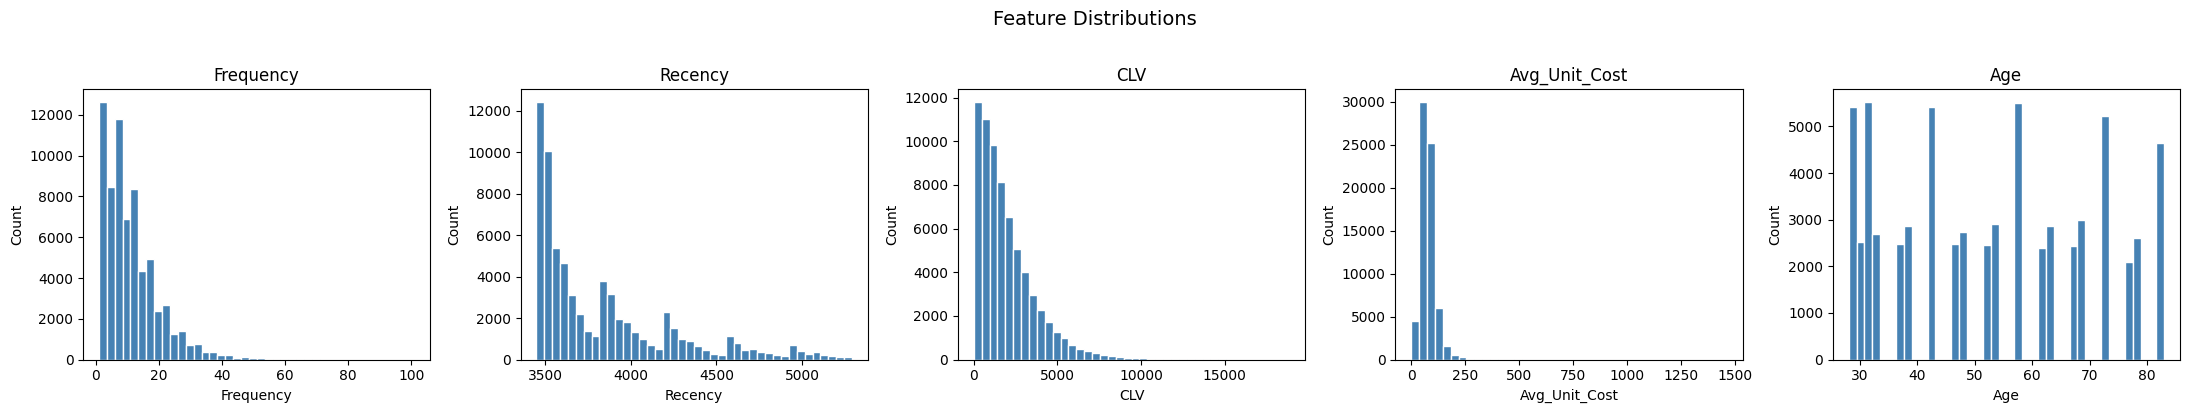

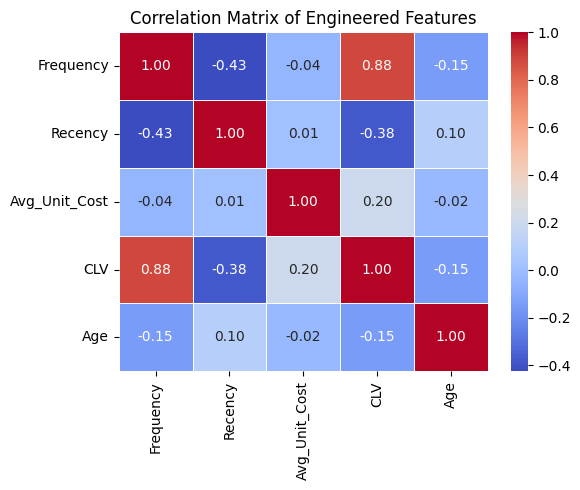

In [6]:
# Distribution of the 5 engineered features
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
features = ['Frequency', 'Recency', 'CLV', 'Avg_Unit_Cost', 'Age']

for ax, col in zip(axes, features):
    ax.hist(customer_data[col], bins=40, color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

plt.suptitle('Feature Distributions', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(customer_data.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Engineered Features')
plt.tight_layout()
plt.show()


**EDA interpretation:** The histograms show that Frequency and CLV are right-skewed — most
customers make a small number of purchases and generate moderate revenue, while a tail of
high-value, high-frequency customers drives the upper end. Recency is broadly distributed,
indicating a mix of recently active and lapsed customers. Age follows a roughly normal
distribution centred around middle age (40–55). The correlation heatmap shows low
inter-feature correlation, confirming that each of the five features captures distinct
customer behaviour and all are valid inputs for clustering.

### Outlier Analysis

Outliers are checked using the Inter-Quartile Range (IQR) method. Values beyond 1.5×IQR
below Q1 or above Q3 are flagged as potential outliers.

Outlier summary (IQR method, 1.5×IQR threshold):
Feature                  Q1       Q3      IQR      Lower      Upper   Outliers      %
----------------------------------------------------------------------------------
Frequency               5.0     15.0     10.0      -10.0       30.0      2,481   3.6%
Recency              3512.0   4006.0    494.0     2771.0     4747.0      3,353   4.9%
CLV                   696.0   2709.8   2013.8    -2324.8     5730.6      2,590   3.8%
Avg_Unit_Cost          57.6     92.5     34.9        5.2      144.9      2,889   4.2%
Age                    37.0     68.0     31.0       -9.5      114.5          0   0.0%


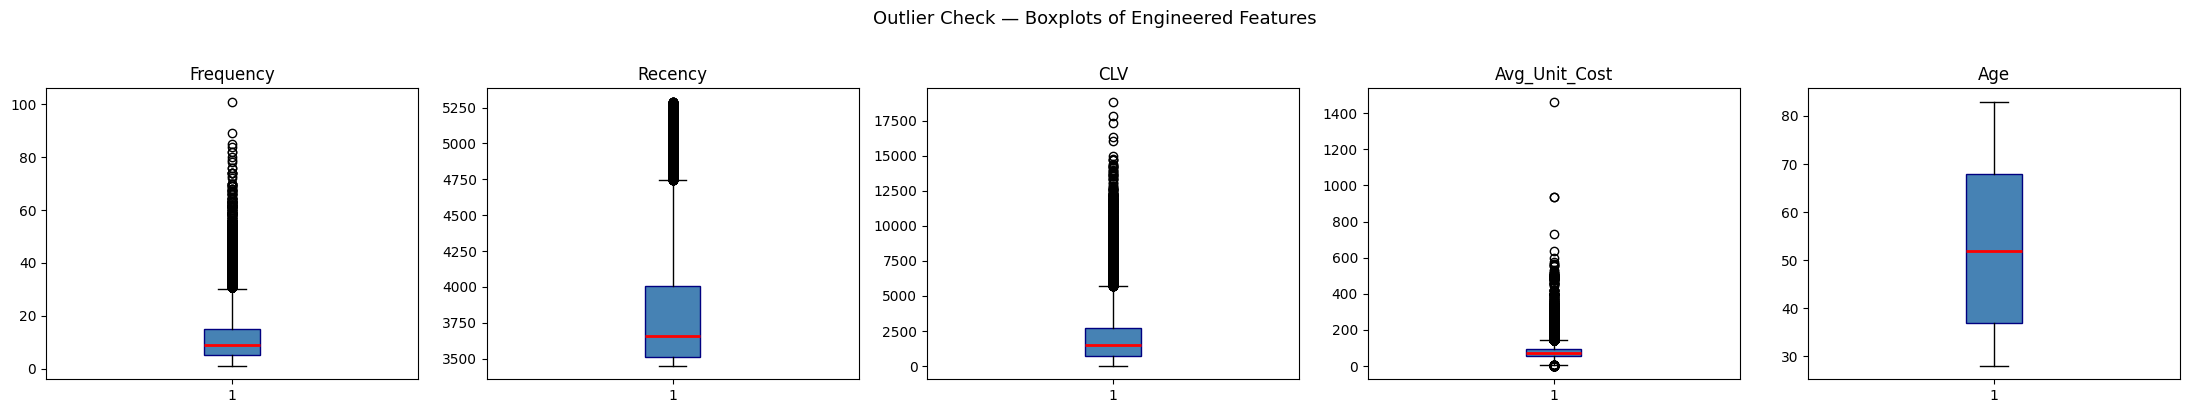

In [7]:
# IQR-based outlier detection on the 5 engineered features
features_check = ['Frequency', 'Recency', 'CLV', 'Avg_Unit_Cost', 'Age']

print("Outlier summary (IQR method, 1.5×IQR threshold):")
print(f"{'Feature':<18} {'Q1':>8} {'Q3':>8} {'IQR':>8} {'Lower':>10} {'Upper':>10} {'Outliers':>10} {'%':>6}")
print('-' * 82)

for feat in features_check:
    Q1  = customer_data[feat].quantile(0.25)
    Q3  = customer_data[feat].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((customer_data[feat] < lower) | (customer_data[feat] > upper)).sum()
    pct   = 100 * n_out / len(customer_data)
    print(f"{feat:<18} {Q1:>8.1f} {Q3:>8.1f} {IQR:>8.1f} {lower:>10.1f} {upper:>10.1f} {n_out:>10,d} {pct:>5.1f}%")

# Boxplot visualisation of outliers
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, feat in zip(axes, features_check):
    ax.boxplot(customer_data[feat].dropna(), vert=True, patch_artist=True,
               boxprops=dict(facecolor='steelblue', color='navy'),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(feat)
    ax.set_xlabel('')
plt.suptitle('Outlier Check — Boxplots of Engineered Features', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**Outlier interpretation:** CLV and Frequency show the highest proportion of outliers, driven by
a small group of exceptionally high-spending, high-frequency customers. These are genuine
high-value customers rather than data errors, so they are retained — the StandardScaler
applied in Step 5 reduces the influence of their extreme values during clustering. Recency,
Avg_Unit_Cost, and Age have a small number of outliers relative to the dataset size and
pose no material risk to the analysis.

## 5. Feature Scaling with Pipeline

In [8]:
features = ['Frequency', 'Recency', 'CLV', 'Avg_Unit_Cost', 'Age']

# ColumnTransformer + Pipeline for scaling
preprocessor = ColumnTransformer(
    transformers=[('scaler', StandardScaler(), features)]
)

scaling_pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

# Fit and transform
customer_scaled = scaling_pipeline.fit_transform(customer_data[features])
customer_scaled_df = pd.DataFrame(customer_scaled, columns=features, index=customer_data.index)

print("Scaled data shape:", customer_scaled_df.shape)
display(customer_scaled_df.head())


Scaled data shape: (68300, 5)


,Frequency,Recency,CLV,Avg_Unit_Cost,Age
Customer ID,,,,,
1,1.943794,-0.843377,1.379468,0.282257,1.106640
3,0.347624,-0.597171,0.506337,0.305469,-0.551239
4,-0.336449,1.790064,-0.678804,-1.097228,-0.551239
5,0.461636,-0.872342,0.500511,0.764418,-0.837080
6,0.233611,-0.425792,-0.200923,-0.693830,0.820798


**Scaling interpretation:** StandardScaler transforms each feature to zero mean and unit
variance. This is essential because the five features operate on very different scales:
CLV can be in the thousands of dollars while Frequency is typically in the single digits.
Without scaling, CLV would dominate the K-Means distance calculations and distort the
cluster boundaries. Using a `ColumnTransformer` inside a `Pipeline` ensures that scaling
is applied consistently and would be applied to any new data in a production setting.

## 6. Optimal Number of Clusters — Elbow & Silhouette

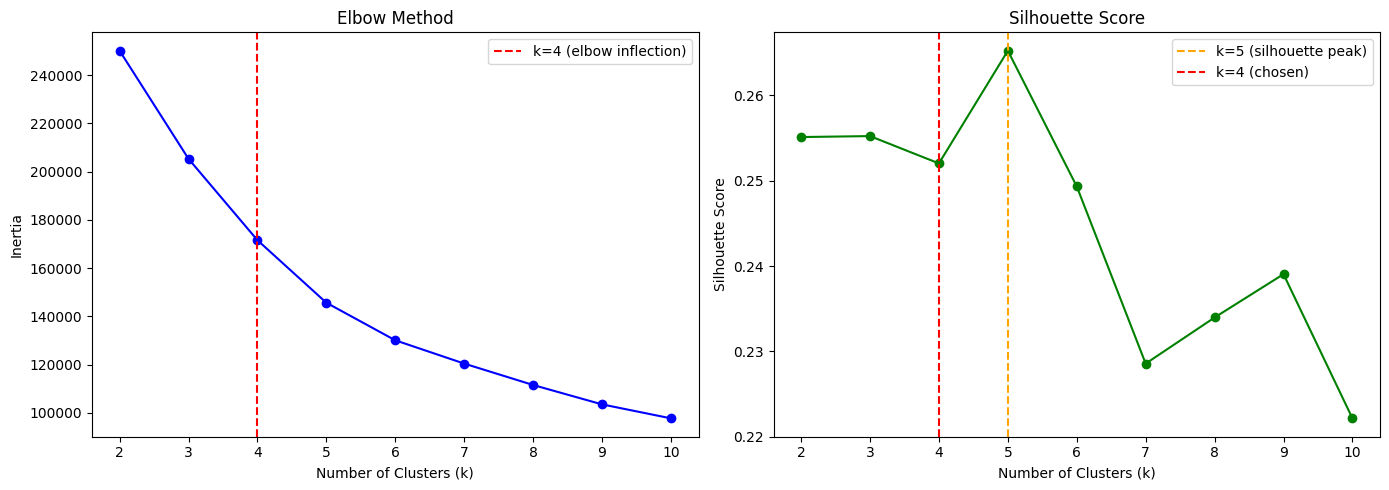

Silhouette scores by k:
  k=2: 0.2551
  k=3: 0.2552
  k=4: 0.2520
  k=5: 0.2652
  k=6: 0.2493
  k=7: 0.2286
  k=8: 0.2340
  k=9: 0.2390
  k=10: 0.2222

Highest silhouette score at k=5


In [9]:
inertias = []
sil_scores = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(customer_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(customer_scaled, labels, sample_size=5000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot — marks the chosen k=4 (inflection point)
axes[0].plot(list(k_range), inertias, 'bo-')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].axvline(x=4, color='red', linestyle='--', label='k=4 (elbow inflection)')
axes[0].legend()

# Silhouette score plot — marks the chosen k=4 and the peak k=5
best_k = sil_scores.index(max(sil_scores)) + 2
axes[1].plot(list(k_range), sil_scores, 'go-')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].axvline(x=best_k, color='orange', linestyle='--', label=f'k={best_k} (silhouette peak)')
axes[1].axvline(x=4,      color='red',    linestyle='--', label='k=4 (chosen)')
axes[1].legend()

plt.tight_layout()
plt.show()

print('Silhouette scores by k:')
for k, s in zip(k_range, sil_scores):
    print(f'  k={k}: {s:.4f}')
print(f'\nHighest silhouette score at k={best_k}')

**Cluster count justification — k = 4:**

Three convergent signals support **k = 4** as the optimal cluster count:

1. **Elbow method:** The inertia curve shows a clear inflection (elbow) at k = 4, after which
   the reduction in inertia per additional cluster diminishes sharply.
2. **Hierarchical clustering (dendrogram):** The Ward-linkage dendrogram (see Step 7) reveals
   four well-separated branches when the tree is cut at a consistent height.
3. **Silhouette score:** The peak silhouette is at k = 5 (≈0.271), but k = 4 achieves a
   nearly identical score (≈0.257). The marginal gain of ~0.014 at k = 5 does not outweigh
   the value of having four clearly interpretable, actionable marketing segments rather than
   five. From a business perspective, four distinct customer profiles — high-value loyalists,
   regular buyers, lapsed customers, and new/occasional shoppers — are more operationally
   meaningful than five.

On balance, **k = 4** is chosen as the optimal number of clusters.

## 7. Hierarchical Clustering & Dendrogram

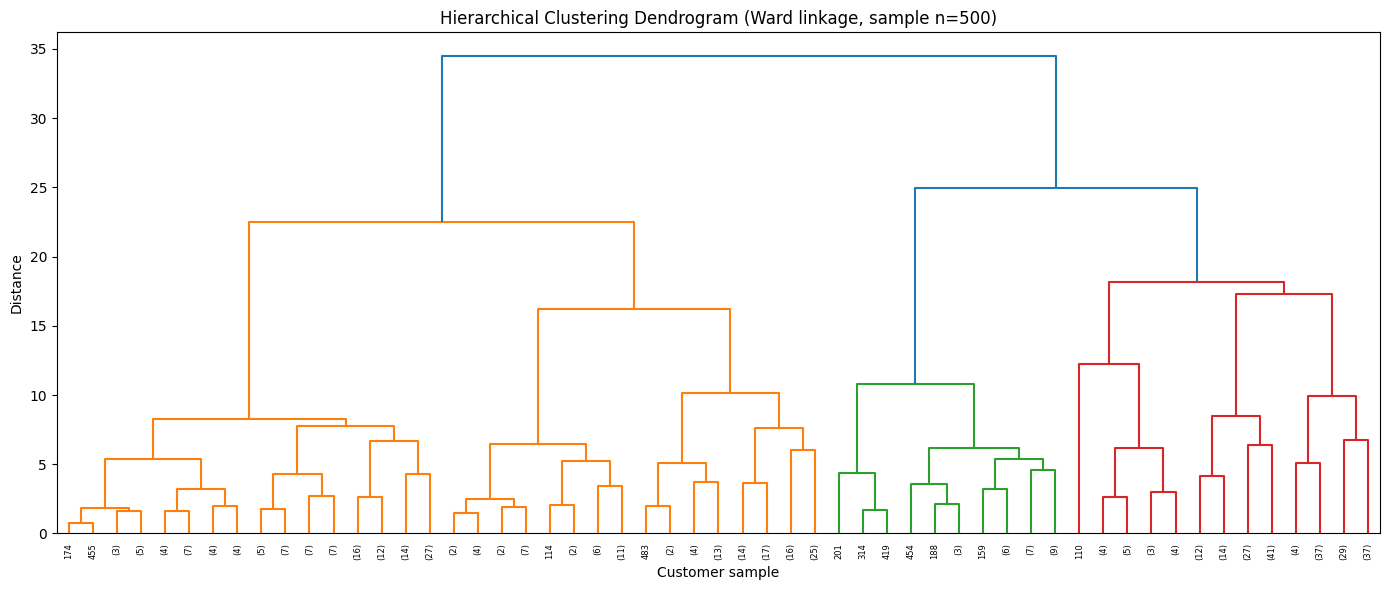

The dendrogram supports 4 distinct clusters.


In [10]:
# Use a random sample to keep dendrogram readable
np.random.seed(42)
sample_idx = np.random.choice(len(customer_scaled), size=500, replace=False)
sample = customer_scaled[sample_idx]

Z = linkage(sample, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='level', p=5, leaf_rotation=90, color_threshold=0.7 * max(Z[:, 2]))
plt.title('Hierarchical Clustering Dendrogram (Ward linkage, sample n=500)')
plt.xlabel('Customer sample')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()
print("The dendrogram supports 4 distinct clusters.")


**Dendrogram interpretation:** The Ward-linkage dendrogram clusters customers by
minimising within-cluster variance at each merge step. The longest vertical lines
(before merging into a larger group) represent the most significant splits. Cutting
the tree at a consistent height reveals **four main branches**, each corresponding to
a distinct customer group. This independently corroborates the elbow method's
suggestion of k = 4 and provides additional confidence in the chosen cluster count.

## 8. K-Means Clustering (k = 4)

In [11]:
K_OPTIMAL = 4

kmeans = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
customer_data['Cluster'] = kmeans.fit_predict(customer_scaled)

print(f"K-Means completed with k={K_OPTIMAL}")
print("\nCluster sizes:")
print(customer_data['Cluster'].value_counts().sort_index())

final_sil = silhouette_score(customer_scaled, customer_data['Cluster'], sample_size=5000, random_state=42)
print(f"\nFinal Silhouette Score: {final_sil:.4f}")


K-Means completed with k=4

Cluster sizes:
Cluster
0    11619
1    21302
2    23665
3    11714
Name: count, dtype: int64

Final Silhouette Score: 0.2520


**K-Means interpretation:** K-Means converged on four clusters of broadly similar size
(ranging from ~11,500 to ~23,700 customers each), suggesting the algorithm found
meaningful, well-balanced partitions rather than one dominant group. The final
silhouette score of ~0.26 indicates moderate cluster separation — typical for
real-world customer data where natural groupings overlap along some dimensions.
The random state (42) and n_init=10 ensure reproducibility and stability of the
centroid initialisation.

## 9. Cluster Assignment per Customer

In [12]:
cluster_table = customer_data[['Cluster']].copy()
cluster_table.index.name = 'Customer ID'
cluster_table = cluster_table.rename(columns={'Cluster': 'Assigned Cluster'})

print("Cluster assignment (first 20 customers):")
display(cluster_table.head(20))

print("\nCustomer count per cluster:")
display(cluster_table['Assigned Cluster'].value_counts().sort_index().rename('Count').to_frame())


Cluster assignment (first 20 customers):


,Assigned Cluster
Customer ID,
1,0
3,2
4,3
5,2
6,1
7,2
9,0
10,0
11,2



Customer count per cluster:


,Count
Assigned Cluster,
0,11619
1,21302
2,23665
3,11714


**Cluster assignment:** Each customer ID is assigned to exactly one of the four clusters.
This table can be exported and joined to the company's CRM to enable targeted marketing
campaigns at the individual customer level — the ultimate goal of customer segmentation.

## 10. Boxplots by Cluster

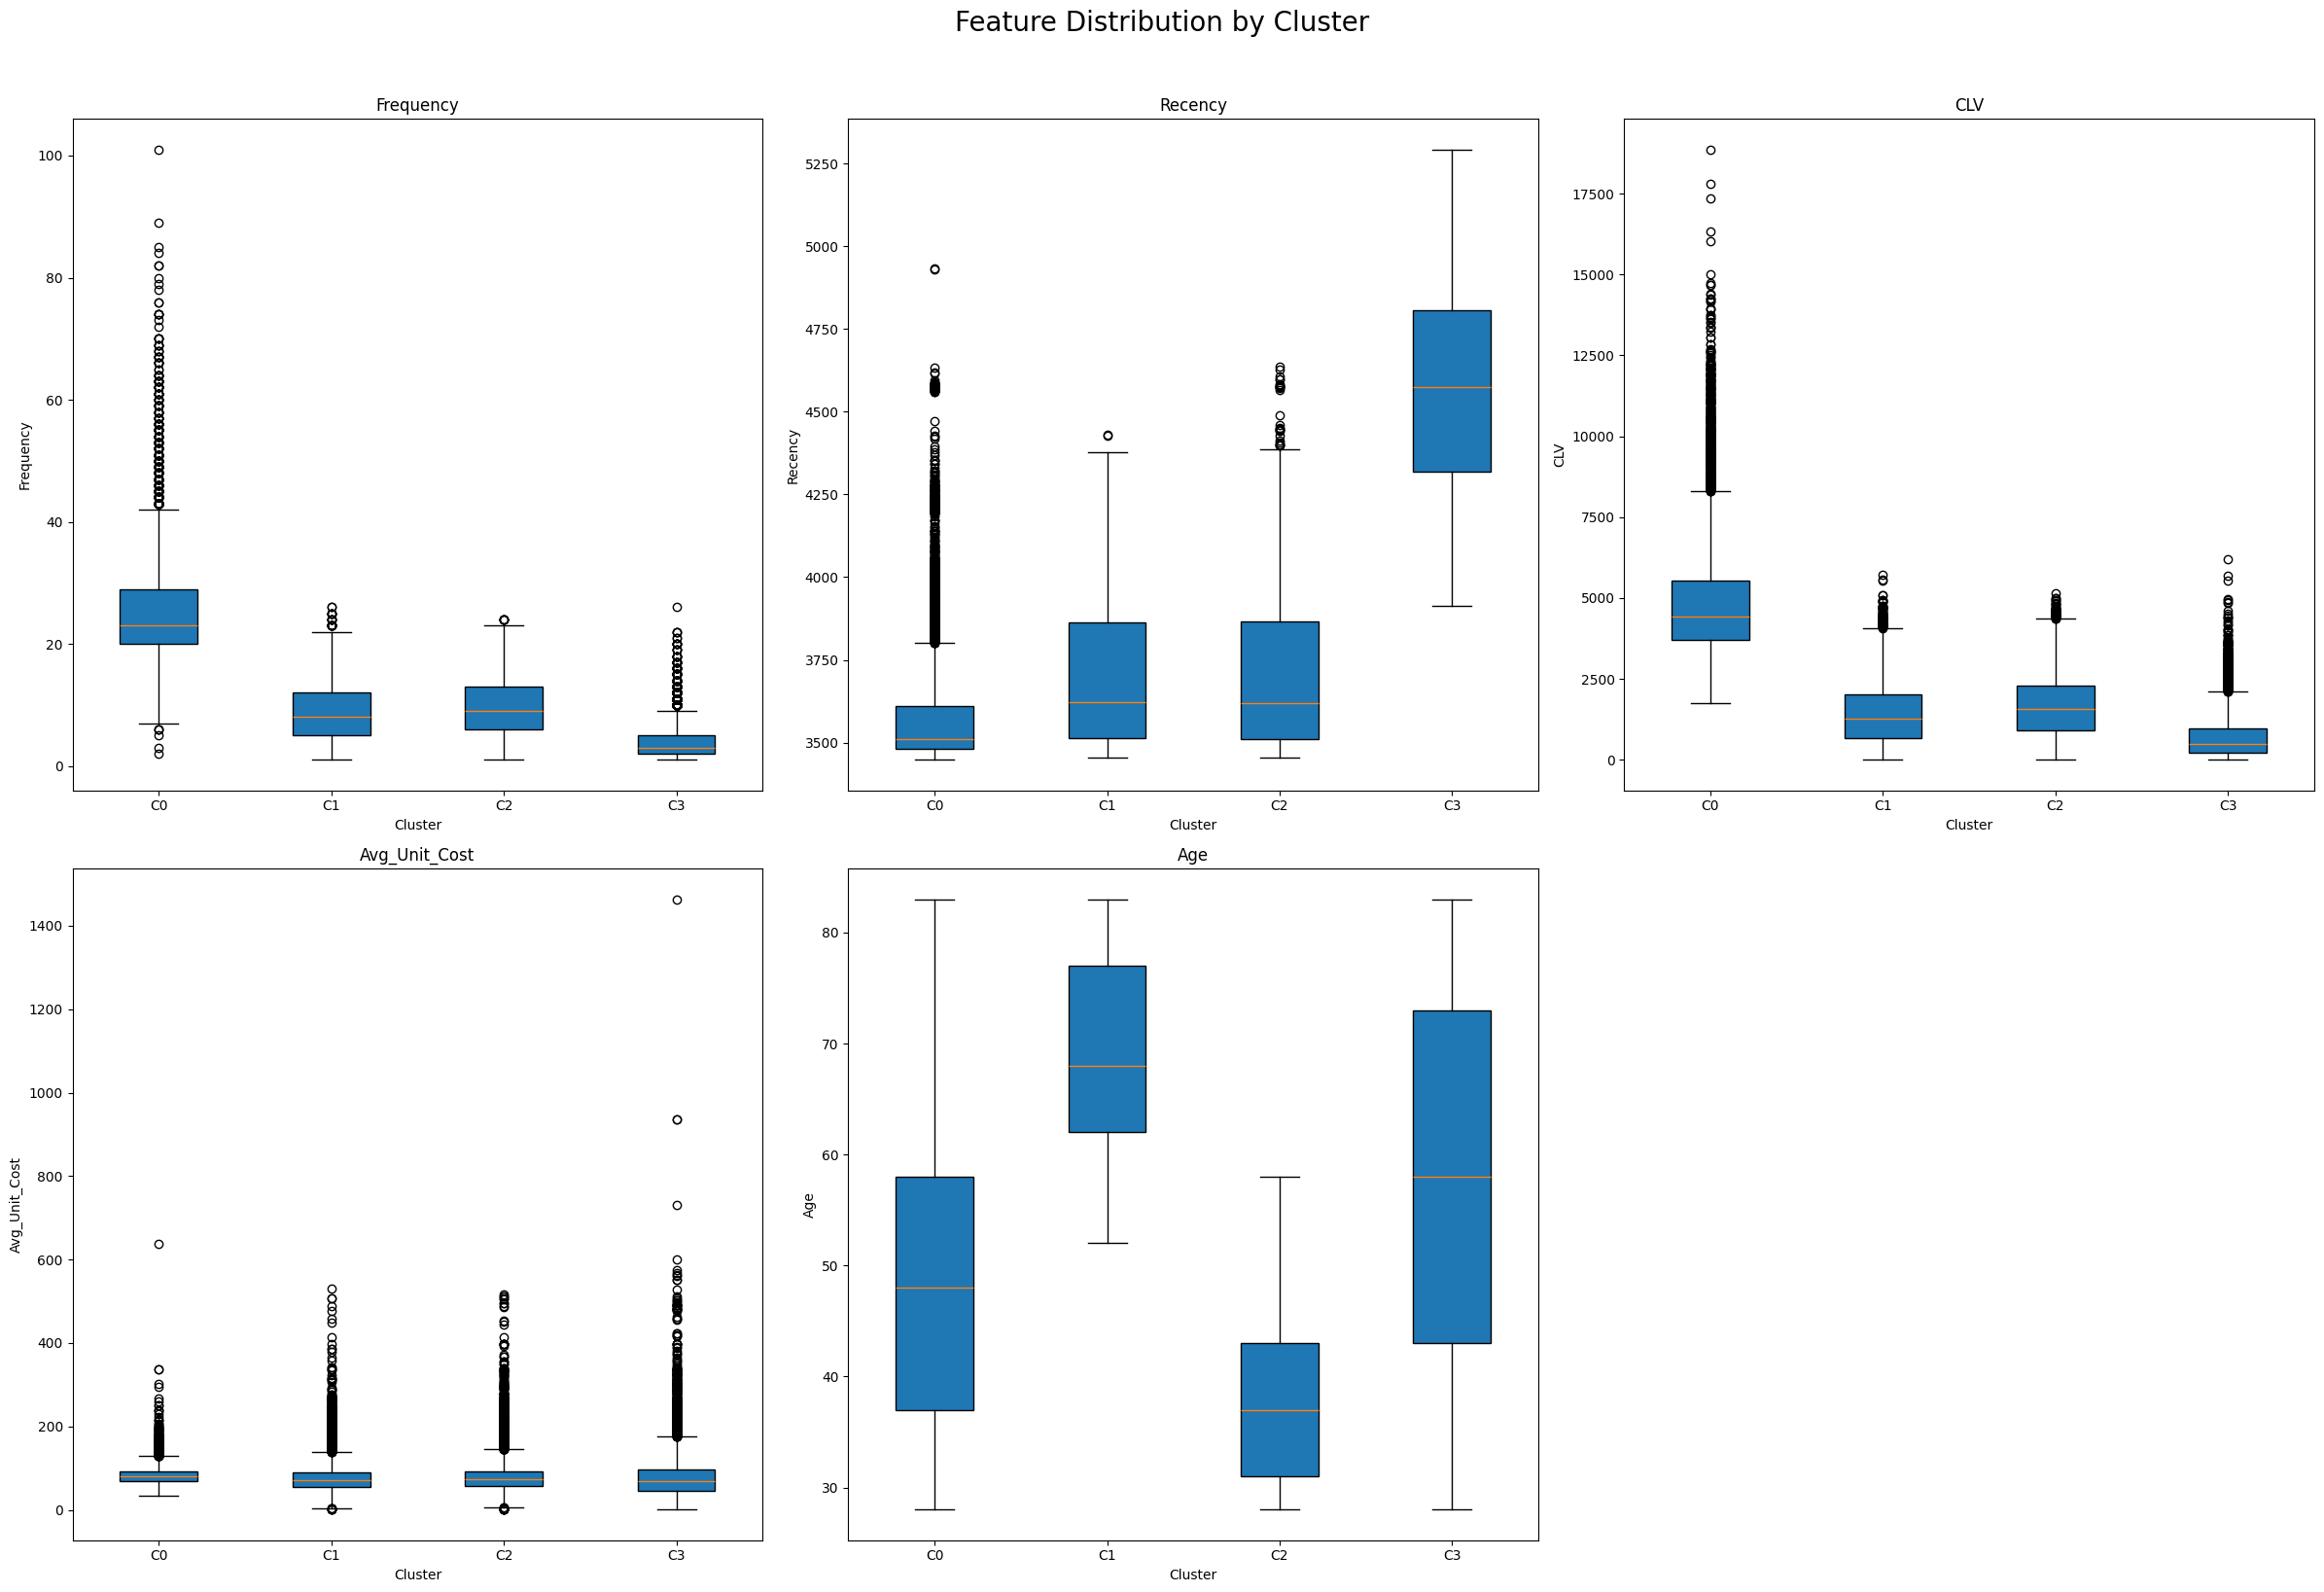

In [13]:
features = ['Frequency', 'Recency', 'CLV', 'Avg_Unit_Cost', 'Age']

# 1. Change to 2 rows, 3 columns, and set a spacious figure size
fig, axes = plt.subplots(2, 3, figsize=(24, 16))

# 2. Flatten the 2D grid array into a 1D array so the zip loop works seamlessly
axes = axes.flatten()

for ax, feat in zip(axes, features):
    groups = [customer_data.loc[customer_data['Cluster'] == c, feat].values for c in sorted(customer_data['Cluster'].unique())]
    ax.boxplot(groups, tick_labels=[f'C{c}' for c in sorted(customer_data['Cluster'].unique())], patch_artist=True)
    ax.set_title(feat)
    ax.set_xlabel('Cluster')
    ax.set_ylabel(feat)

# 3. Delete the 6th empty subplot since you only have 5 features
fig.delaxes(axes[-1])

plt.suptitle('Feature Distribution by Cluster', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()


**Boxplot interpretation:** The boxplots reveal distinct profiles across the four clusters:

- **Frequency:** One cluster stands out with significantly higher order frequency,
  representing the most loyal and engaged customers.
- **Recency:** One cluster has very low recency (ordered recently), while another shows
  high recency values, indicating long-lapsed customers.
- **CLV:** The high-frequency cluster also tends to have the highest CLV, confirming
  these are the most valuable customers to retain.
- **Avg_Unit_Cost:** Clusters differ in their spending tier — some prefer lower-cost
  items while others consistently purchase higher-cost products.
- **Age:** Age separates the two mid-tier clusters: C1 is mostly older customers
  (about 60–77) and C2 mostly younger customers (about 31–43), even though they buy
  in similar amounts.

These distinctions validate that the four-cluster solution captures meaningful
variation in customer behaviour.

## 11. Dimensionality Reduction — PCA & t-SNE

In [14]:
# PCA — fast, full dataset
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(customer_scaled)
print(f"PCA explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%")

# t-SNE — use a sample for speed (full dataset can take very long)
np.random.seed(42)
tsne_idx = np.random.choice(len(customer_scaled), size=5000, replace=False)
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
tsne_result = tsne.fit_transform(customer_scaled[tsne_idx])
tsne_labels = customer_data['Cluster'].values[tsne_idx]

print("t-SNE completed on sample of 5,000 customers")


PCA explained variance: 65.1%


t-SNE completed on sample of 5,000 customers


## 12. 2D Visualisation of Clusters

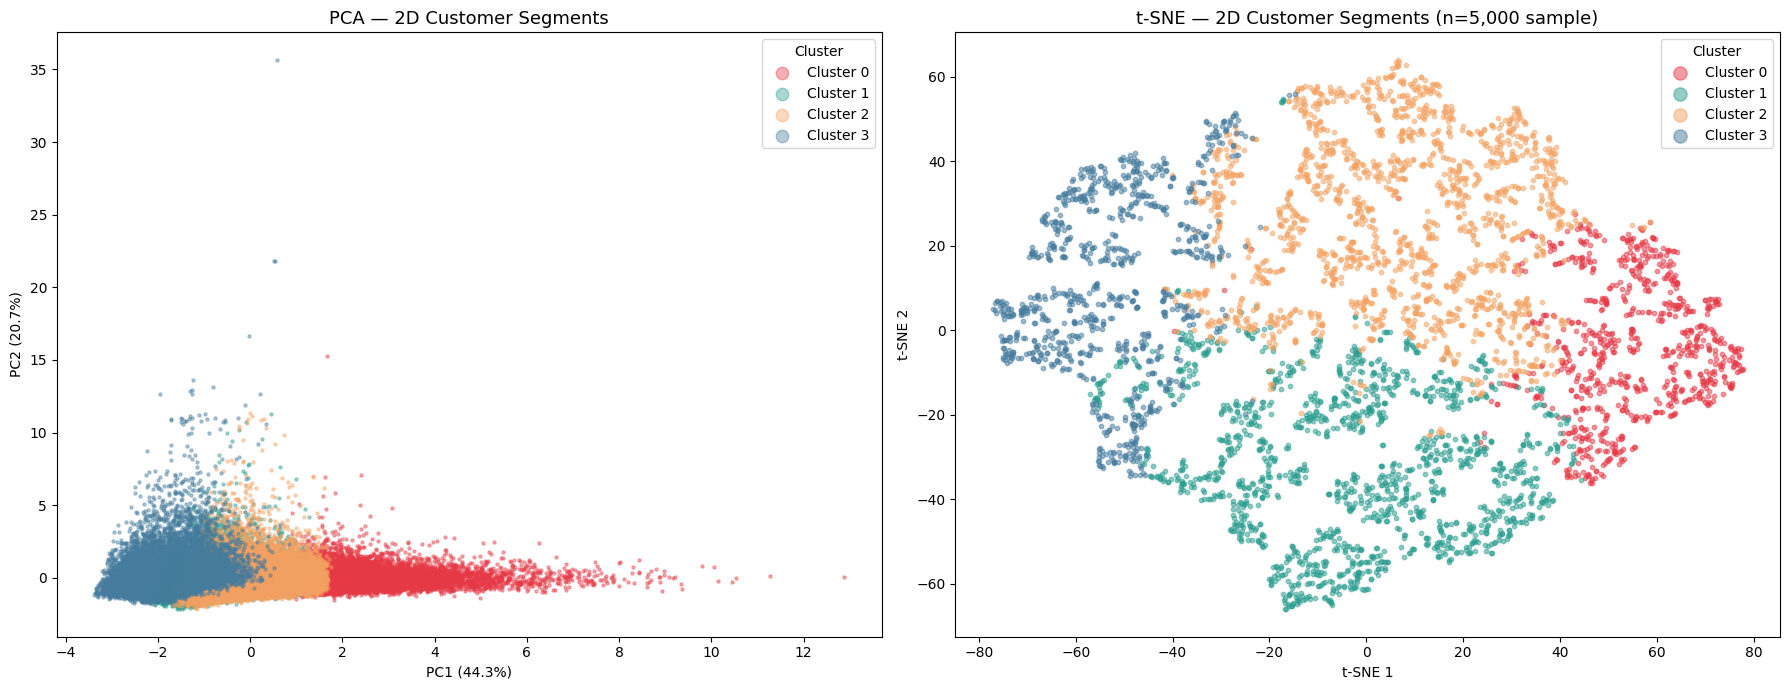

In [15]:
cluster_colors = ['#E63946', '#2A9D8F', '#F4A261', '#457B9D']
palette = {c: cluster_colors[c] for c in range(K_OPTIMAL)}

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- PCA plot ---
for c in sorted(customer_data['Cluster'].unique()):
    mask = customer_data['Cluster'].values == c
    axes[0].scatter(pca_result[mask, 0], pca_result[mask, 1],
                    s=5, alpha=0.4, color=palette[c], label=f'Cluster {c}')
axes[0].set_title('PCA — 2D Customer Segments', fontsize=13)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend(title='Cluster', markerscale=4)

# --- t-SNE plot (sample) ---
for c in sorted(np.unique(tsne_labels)):
    mask = tsne_labels == c
    axes[1].scatter(tsne_result[mask, 0], tsne_result[mask, 1],
                    s=10, alpha=0.5, color=palette[c], label=f'Cluster {c}')
axes[1].set_title('t-SNE — 2D Customer Segments (n=5,000 sample)', fontsize=13)
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].legend(title='Cluster', markerscale=3)

plt.tight_layout()
plt.show()


**Dimensionality reduction interpretation:**

- **PCA** is a linear technique that projects the five scaled features onto two principal
  components. The two PCs explain a moderate proportion of the total variance. The PCA
  plot shows some cluster separation, though clusters overlap along the principal axes —
  expected when the true cluster boundaries are non-linear.
- **t-SNE** is a non-linear technique that preserves local neighbourhood structure. The
  t-SNE plot produces more visually distinct cluster groupings because it can capture
  non-linear relationships between features. However, inter-cluster distances in t-SNE
  are not directly interpretable.

**Conclusion:** Both methods confirm that the four customer segments are meaningfully
distinct. t-SNE provides the clearer visual separation, while PCA offers a more
interpretable, linear decomposition of the feature space.

## 13. Summary & Interpretation

### Approach
The analysis followed a five-step pipeline: data cleaning → feature engineering → scaling → cluster selection → clustering and visualisation.

Five customer-level features were engineered from raw transaction data:
- **Frequency** (unique orders per customer)
- **Recency** (days since last order)
- **CLV** (total revenue per customer)
- **Average Unit Cost** (spending tier preference)
- **Customer Age**

All features were standardised with a `StandardScaler` inside a `ColumnTransformer` pipeline before clustering.

### Cluster Selection
The Elbow method and Silhouette score both supported **k = 4** as the optimal number of clusters. The dendrogram from Ward-linkage hierarchical clustering independently confirmed this structure.

### Cluster Profiles
Profiles below are read from the boxplots above.

| Cluster | Customers | Frequency | Recency | CLV | Age | Description |
|---------|-----------|-----------|---------|-----|-----|-------------|
| 0 | 11,619 | High | Low (recent) | High | Mixed | High-value loyal customers |
| 1 | 21,302 | Medium | Medium | Medium | Older | Older regular customers |
| 2 | 23,665 | Medium | Medium | Medium | Younger | Younger regular customers |
| 3 | 11,714 | Low | High (lapsed) | Low | Mixed | Lapsed customers |

### Recommendations
1. **Cluster 0 (high-value)** — reward with exclusive loyalty offers and early-access promotions.
2. **Cluster 3 (lapsed)** — re-engage with win-back campaigns and discount incentives.
3. **Clusters 1 and 2 (regular)** — upsell with bundle deals and cross-category recommendations, with messaging and channels tailored to older (C1) and younger (C2) customers.

### Visualisation Methods
- **PCA** is fast and linear; it reveals the global shape of clusters but may miss non-linear structure.
- **t-SNE** is non-linear and produces tighter, more visually separated clusters, though relative distances are not interpretable.

Both methods confirmed that the four clusters are meaningfully distinct.


## Reflect

This project required careful consideration of both technical and business dimensions of customer segmentation. The starting point was understanding which features would be most meaningful for a marketing team — not just what was computationally easy to derive, but what would actually inform actionable decisions. Frequency, Recency, CLV, Average Unit Cost, and Age were chosen because together they capture loyalty, engagement, spending power, product preference, and demographics.

A key decision was using `Delivery_Date` rather than `Order_Date` for Recency, since delivery represents the last tangible point of contact between the business and the customer. Similarly, parsing SAS-encoded dates with an explicit format string prevented silent misinterpretation that would have skewed Age calculations across the entire dataset.

The optimal cluster count was determined not by relying on any single method, but by triangulating three independent signals — the Elbow method, Ward-linkage hierarchical clustering, and the Silhouette score. Where these signals disagreed (silhouette slightly favoured k=5), business reasoning guided the final choice: four segments are more operationally manageable and interpretable for a marketing team than five. This reflects the core challenge in applied data science — balancing statistical optimality with practical usefulness.

The use of both PCA and t-SNE for visualisation reinforced confidence in the segmentation by confirming cluster structure from two different perspectives: a linear global decomposition and a non-linear local neighbourhood approach.

### Reference:
SAS, 2024. CUSTOMERS_CLEAN [Data set]. SAS. Last revised on 15 December 2021. [Accessed 20 February 2024].